In [1]:
!git add .
!git commit -m "Insurance Project"
!git push -u origin main

[main 355e138] Insurance Project
 1 file changed, 61 insertions(+), 902 deletions(-)
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 10 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 1.01 KiB | 1.01 MiB/s, done.
Total 3 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/pankajvshnv/Data-Science.git
   bfb22c5..355e138  main -> main
branch 'main' set up to track 'origin/main'.


In [2]:
import pandas as pd


In [3]:
data = pd.read_csv("insurance.csv")
df = data

In [4]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [5]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### EDA

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [7]:
numerical_data = [ "age", "bmi", "children", "charges"]

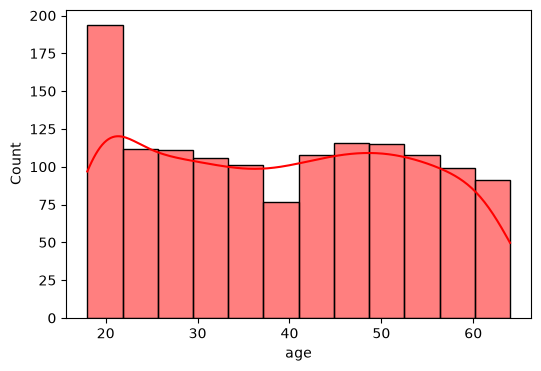

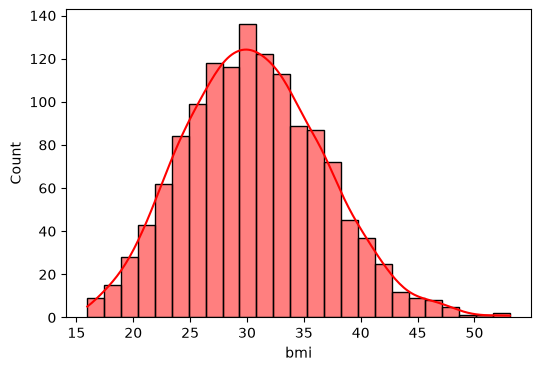

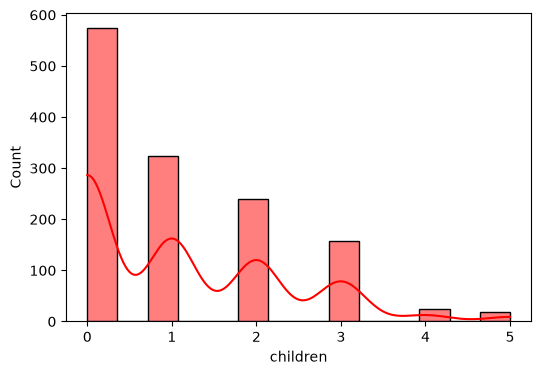

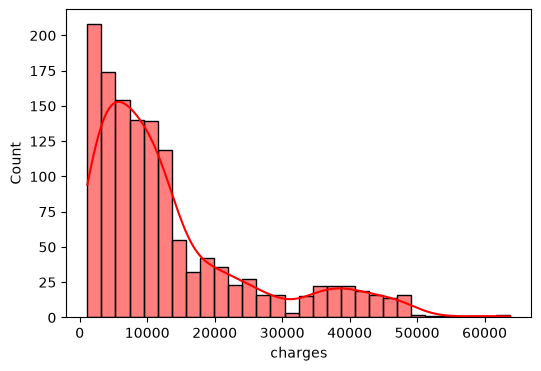

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
for i in numerical_data:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df, x=i, kde=True, color='r')
    plt.show()




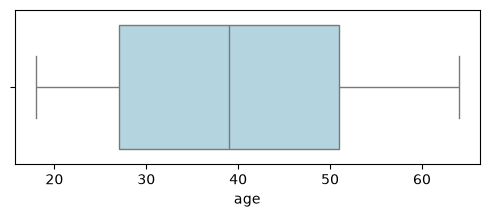

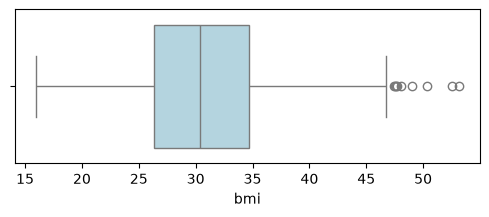

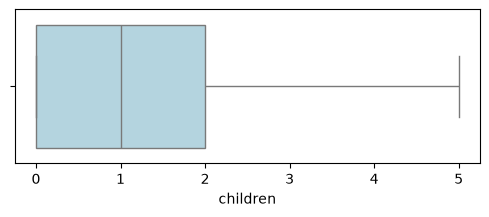

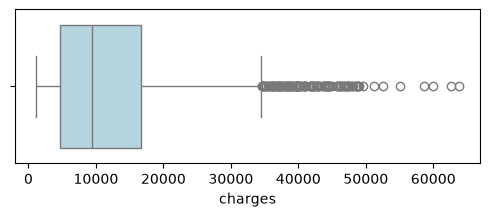

In [9]:
for i in numerical_data:
    plt.figure(figsize=(6, 2))
    sns.boxplot(data=df, x=i, color='lightblue')
    plt.show()

In [10]:
# import numpy as np

# for i in numerical_data:
#     mean = df[i].mean()
#     std_dev = df[i].std()
    
    
#     df['z_score'] = (df[i] - mean) / std_dev
    
 
#     outliers_z = df[np.abs(df['z_score']) > 3]
    
#     print(f"Outliers for {i}:")
#     print(outliers_z[[i, 'z_score']])
#     print("-" * 30)

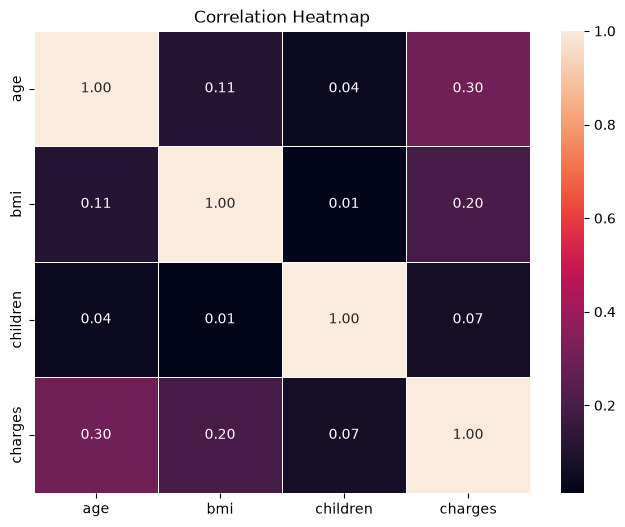

In [11]:
plt.figure(figsize=(8, 6))

corr_matrix = df[numerical_data].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap')
plt.show()

## data cleaning and preprocessing

In [12]:
df.drop_duplicates(inplace = True)

/var/folders/4t/xyd6v_lj5m38ffp9mpcjv05r0000gn/T/ipykernel_46513/3424306917.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace = True)


In [13]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [14]:
df['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

## labeled Encoding

In [15]:
df['sex'] = df['sex'].map({
    "male" : 0,
    "female": 1
        })

In [16]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,no,northwest,10600.54830
1334,18,1,31.920,0,no,northeast,2205.98080
1335,18,1,36.850,0,no,southeast,1629.83350
1336,21,1,25.800,0,no,southwest,2007.94500


In [17]:
df['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [18]:
df['smoker'] = df['smoker'].map({
    "yes": 1,
    "no":0
        })

In [19]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


## One Hot Encoding

In [20]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,northwest,10600.54830
1334,18,1,31.920,0,0,northeast,2205.98080
1335,18,1,36.850,0,0,southeast,1629.83350
1336,21,1,25.800,0,0,southwest,2007.94500


In [21]:
region_df = pd.get_dummies(df['region'], prefix='region', dtype=int)

df = pd.concat([df, region_df], axis=1)

df.drop('region', axis=1, inplace=True)

df.head()

/var/folders/4t/xyd6v_lj5m38ffp9mpcjv05r0000gn/T/ipykernel_46513/2858195568.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('region', axis=1, inplace=True)


,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,0,1
1,18,0,33.770,1,0,1725.55230,0,0,1,0
2,28,0,33.000,3,0,4449.46200,0,0,1,0
3,33,0,22.705,0,0,21984.47061,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0


In [22]:
df = df.astype(int)

In [23]:
df.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   age               1337 non-null   int64
 1   sex               1337 non-null   int64
 2   bmi               1337 non-null   int64
 3   children          1337 non-null   int64
 4   smoker            1337 non-null   int64
 5   charges           1337 non-null   int64
 6   region_northeast  1337 non-null   int64
 7   region_northwest  1337 non-null   int64
 8   region_southeast  1337 non-null   int64
 9   region_southwest  1337 non-null   int64
dtypes: int64(10)
memory usage: 114.9 KB


## Feature Engineering

In [24]:
import numpy as np


bins = [0, 18.5, 25.0, 30.0, np.inf]
labels = ['Underweight', 'Healthy Weight', 'Overweight', 'Obese']


df['bmi_category'] = pd.cut(df['bmi'], bins=bins, labels=labels, right=False)

print(df[['bmi', 'bmi_category']].head(10))

   bmi    bmi_category
0   27      Overweight
1   33           Obese
2   33           Obese
3   22  Healthy Weight
4   28      Overweight
5   25      Overweight
6   33           Obese
7   27      Overweight
8   29      Overweight
9   25      Overweight


In [25]:
# One-hot encode the new bmi_category column
df = pd.get_dummies(df, columns=['bmi_category'], dtype=int)
df.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Healthy Weight,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,0,1,0,0,1,0
1,18,0,33,1,0,1725,0,0,1,0,0,0,0,1
2,28,0,33,3,0,4449,0,0,1,0,0,0,0,1
3,33,0,22,0,0,21984,0,1,0,0,0,1,0,0
4,32,0,28,0,0,3866,0,1,0,0,0,0,1,0


In [26]:
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()

cols_to_scale = ['age', 'bmi', 'children']

df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

df.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Healthy Weight,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,0,1,0,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,0,1,0,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,1,0,0,0,0,1,0


### the most useful thing to do is check how strongly every feature correlates with your target variable    -1______0______+1

## Feature Extraction

Pearson Correlation with 'charges':

charges                        1.000000
smoker                         0.787234
age                            0.298309
bmi_category_Obese             0.200348
bmi                            0.196236
region_southeast               0.073577
children                       0.067390
region_northeast               0.005946
region_northwest              -0.038695
region_southwest              -0.043637
bmi_category_Underweight      -0.050599
sex                           -0.058046
bmi_category_Healthy Weight   -0.104042
bmi_category_Overweight       -0.120601
Name: charges, dtype: float64


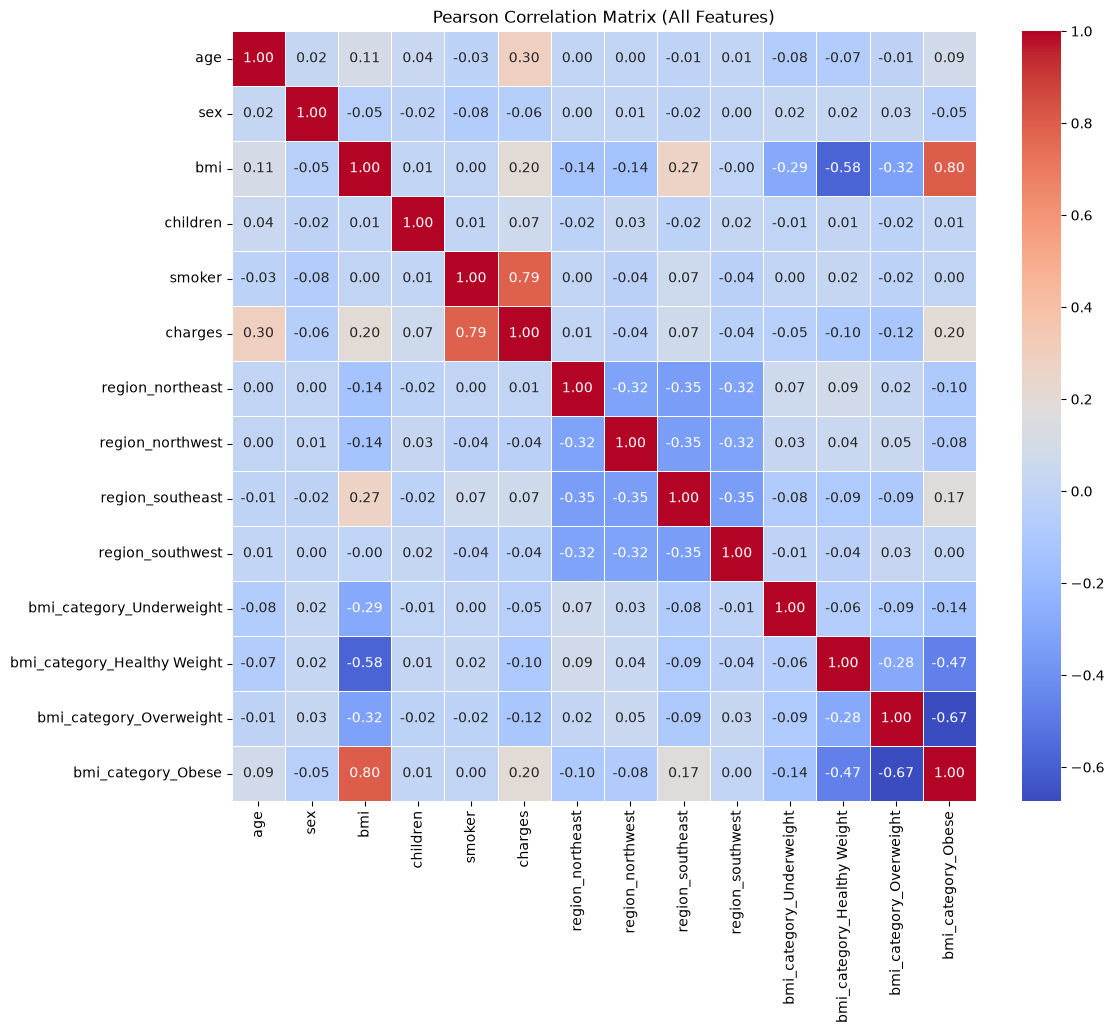

In [27]:

pearson_corr = df.corr(method='pearson')


charges_corr = pearson_corr['charges'].sort_values(ascending=False)

print("Pearson Correlation with 'charges':\n")
print(charges_corr)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Pearson Correlation Matrix (All Features)')
plt.show()

#### Pearson correlation for Linear

Pearson Correlation with 'charges':

charges                        1.000000
smoker                         0.787234
age                            0.298309
bmi_category_Obese             0.200348
bmi                            0.196236
region_southeast               0.073577
children                       0.067390
region_northeast               0.005946
region_northwest              -0.038695
region_southwest              -0.043637
bmi_category_Underweight      -0.050599
sex                           -0.058046
bmi_category_Healthy Weight   -0.104042
bmi_category_Overweight       -0.120601
Name: charges, dtype: float64


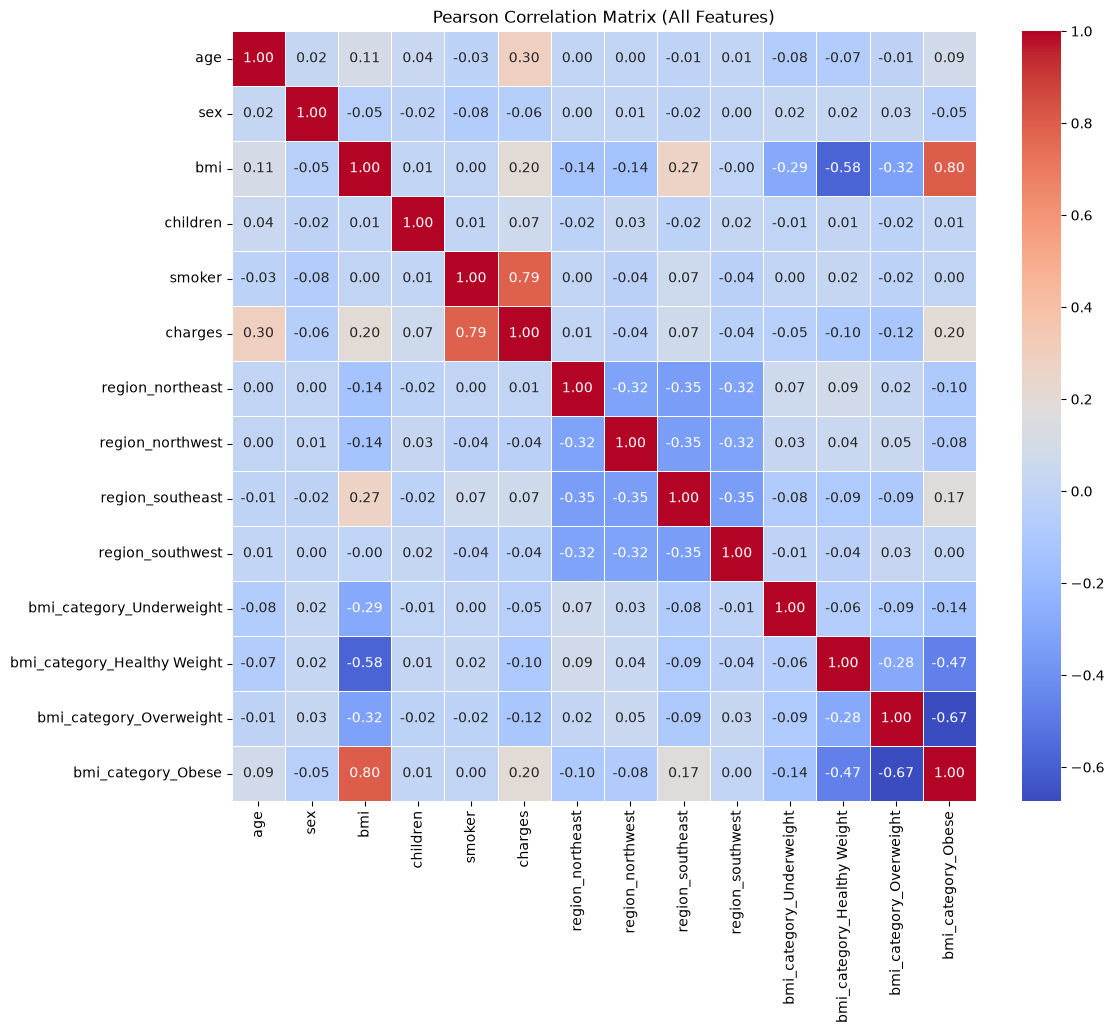

In [28]:

pearson_corr = df.corr(method='pearson')


charges_corr = pearson_corr['charges'].sort_values(ascending=False)

print("Pearson Correlation with 'charges':\n")
print(charges_corr)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))

sns.heatmap(pearson_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Pearson Correlation Matrix (All Features)')
plt.show()

In [29]:
from scipy.stats import chi2_contingency
import pandas as pd

# Define your categorical columns based on the encoding we did earlier
cat_features = [
    'sex', 'smoker', 
    'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Underweight', 'bmi_category_Healthy Weight', 'bmi_category_Overweight', 'bmi_category_Obese'
]

alpha = 0.05

# 1. Convert the continuous 'charges' into 4 categories (quartiles)
df['charges_bin'] = pd.qcut(df['charges'], q=4, labels=False)
chi2_results = {}

# 2. Run the Chi-Square test for each feature against the binned charges
for col in cat_features:
    # Ensure the column exists in the dataframe before testing
    if col in df.columns:
        contingency = pd.crosstab(df[col], df['charges_bin'])
        chi2_stat, p_val, _, _ = chi2_contingency(contingency)
        
        decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
        
        chi2_results[col] = {
            'chi2_statistic': round(chi2_stat, 2),
            'p_value': round(p_val, 4),
            'Decision': decision
        }

# 3. Convert the results dictionary into a Pandas DataFrame for easy reading
results_df = pd.DataFrame(chi2_results).T
display(results_df)

,chi2_statistic,p_value,Decision
sex,10.26,0.0165,Reject Null (Keep Feature)
smoker,848.22,0.0,Reject Null (Keep Feature)
region_northeast,6.44,0.0921,Accept Null (Drop Feature)
region_northwest,1.13,0.7688,Accept Null (Drop Feature)
region_southeast,16.0,0.0011,Reject Null (Keep Feature)
region_southwest,5.09,0.1652,Accept Null (Drop Feature)
bmi_category_Underweight,3.37,0.3375,Accept Null (Drop Feature)
bmi_category_Healthy Weight,3.71,0.2948,Accept Null (Drop Feature)
bmi_category_Overweight,4.25,0.2356,Accept Null (Drop Feature)
bmi_category_Obese,8.52,0.0365,Reject Null (Keep Feature)


In [30]:

final_df = df[['age', 'bmi', 'sex', 'children', 'smoker', 'region_southeast', 'bmi_category_Obese', 'charges']]

final_df.head()

,age,bmi,sex,children,smoker,region_southeast,bmi_category_Obese,charges
0,-1.440418,-0.517949,1,-0.909234,1,0,0,16884
1,-1.511647,0.462463,0,-0.079442,0,1,1,1725
2,-0.799350,0.462463,0,1.580143,0,1,1,4449
3,-0.443201,-1.334960,0,-0.909234,0,0,0,21984
4,-0.514431,-0.354547,0,-0.909234,0,0,0,3866


In [31]:
final_df

,age,bmi,sex,children,smoker,region_southeast,bmi_category_Obese,charges
0,-1.440418,-0.517949,1,-0.909234,1,0,0,16884
1,-1.511647,0.462463,0,-0.079442,0,1,1,1725
2,-0.799350,0.462463,0,1.580143,0,1,1,4449
3,-0.443201,-1.334960,0,-0.909234,0,0,0,21984
4,-0.514431,-0.354547,0,-0.909234,0,0,0,3866
...,...,...,...,...,...,...,...,...
1333,0.767704,-0.027743,0,1.580143,0,0,1,10600
1334,-1.511647,0.135659,1,-0.909234,0,0,1,2205
1335,-1.511647,0.952670,1,-0.909234,0,1,1,1629
1336,-1.297958,-0.844753,1,-0.909234,0,0,0,2007


In [32]:
from sklearn.model_selection import train_test_split
x = final_df.drop("charges", axis= 1)
y = final_df["charges"]

In [34]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

